# HNSW molecule viewer
Extract this package into the Chemtellect repository, keeping the notebooks/ and scripts/ directories. Open this notebook with the project's Jupyter kernel and run all cells. Select an experiment and size in the first cell. The loader verifies the existing run and opens its exact score matrix read-only. To explore more queries or cutoffs on the same sample, rerun only the last cell.

In [3]:
from pathlib import Path
import sys

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/chemtellect').is_dir())
sys.path.insert(0, str(ROOT / 'scripts'))
from chemtellect.hnsw_molecule_viewer import load_run, show_query
EXPERIMENT = 'experiments/results/pipeline/chemicalspace_new/scale_1m_00/experiment_20261112_0333'
INDEX_SIZE = 1_000_000
data = load_run(ROOT, EXPERIMENT, INDEX_SIZE)
print(data['path'])
print('Saved k values:', list(data['report']['benchmark']['designated']['hnsw']))


Your CPU supports instructions that this binary was not compiled to use: SSE3 SSE4.1 SSE4.2 AVX AVX2
For maximum performance, you can install NMSLIB from sources 
pip install --no-binary :all: nmslib


/home/ruben/Coding Projects/chemtellect/experiments/results/hnsw/chemicalspace_new/scale_1m_00/56bac75d9e8bda73ed809c821e61f381f7196c74fcdf87d7a4f0babce0d569c0/index_1000000/run_ea2725c6bba24a8986eb54e24d1c76ba
Saved k values: ['10', '100', '25', '50']


## Choose a query and display cutoff
Row 85 is the 86th molecule in the saved query split. Use row 84 for the 85th molecule. Ranks are the original HNSW ranks. A cutoff of 0 shows every returned compound. The red cards show up to two missed exact top-k slots, including below-cutoff misses unless you turn on the missed-neighbor filter. An equally scoring replacement at the kth boundary receives credit. An example from a tied group represents one missing slot whose identity is ambiguous.


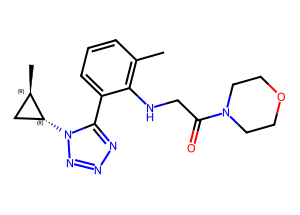
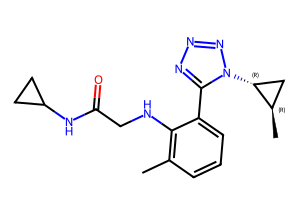
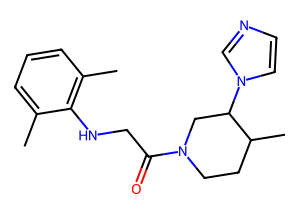
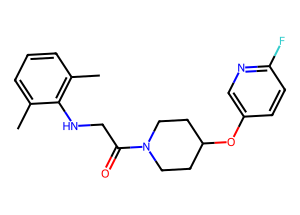
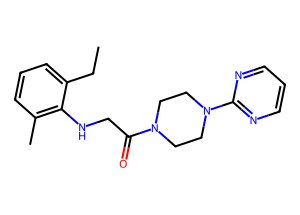
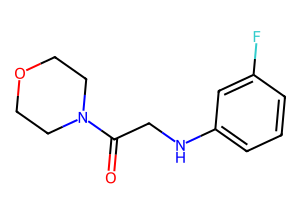
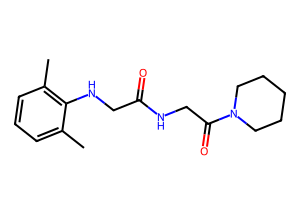
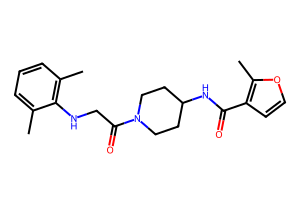
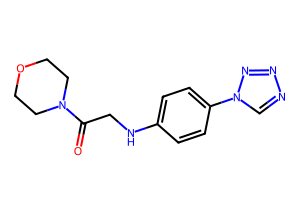
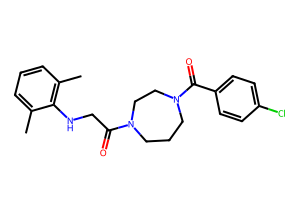
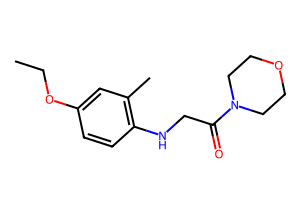
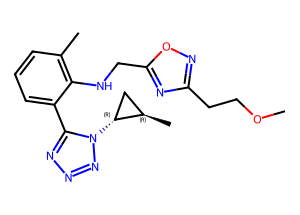

In [7]:
QUERY_ROW = 12
K = 10
MIN_TANIMOTO = 0.30
FILTER_MISSES_TOO = False

show_query(data, query_row=QUERY_ROW, k=K, cutoff=MIN_TANIMOTO,
           filter_misses=FILTER_MISSES_TOO)
